# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Yuri Naufal Akhdan
- NIM   : 241011402952
- Kelas : Reg B / Reg C

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

In [4]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM 241011402952 adalah 52
RANDOM_STATE = 52

In [5]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples = len(X)
    shuffled_indices = np.random.permutation(n_samples)

    test_set_size = int(n_samples * test_size)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]

    if isinstance(X, (pd.DataFrame, pd.Series)):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]

    if isinstance(y, (pd.DataFrame, pd.Series)):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

--- 5 Data Pertama Ads_Data.csv ---
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


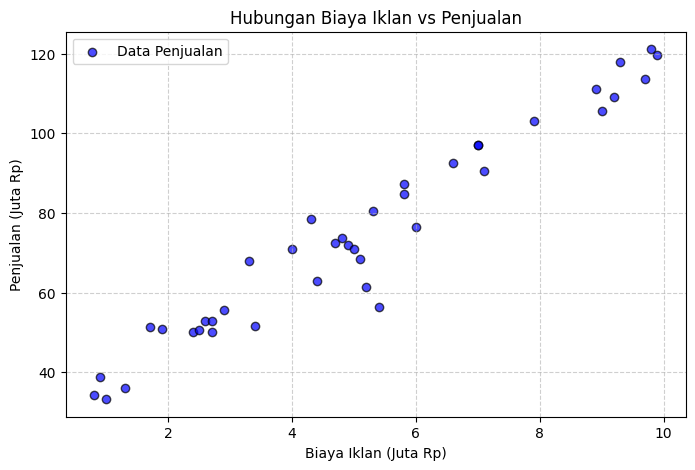

In [6]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')

print("--- 5 Data Pertama Ads_Data.csv ---")
print(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)}")

X_ads = df_ads[['BiayaIklan']].values # Shape (n, 1)
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, edgecolors='k', label='Data Penjualan')
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [7]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test : {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test : {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [8]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta_best[0]
        self.coef_ = theta_best[1:]

    def predict(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.r_[self.intercept_, self.coef_]
        return X_b.dot(theta)

model_lr = LinearRegression()
model_lr.fit(X_train_ads, y_train_ads)

print(f"Intercept (b) : {model_lr.intercept_:.4f}")
print(f"Koefisien (m) : {model_lr.coef_[0]:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {model_lr.intercept_:.4f} + {model_lr.coef_[0]:.4f} * BiayaIklan")

Intercept (b) : 29.4375
Koefisien (m) : 9.0091
Persamaan Garis Regresi: y_hat = 29.4375 + 9.0091 * BiayaIklan


**Jawaban A3 (interpretasi):**

Nilai koefisien $m$ mengindikasikan bahwa **setiap kenaikan biaya iklan sebesar 1 juta Rp, maka estimasi penjualan akan meningkat secara rata-rata sebesar nilai $m$ (dalam juta Rp)**. Nilai intercept $b$ menunjukkan perkiraan baseline penjualan ketika tidak ada biaya iklan sama sekali (biaya iklan = 0).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [9]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_pred_train_ads = model_lr.predict(X_train_ads)
y_pred_test_ads = model_lr.predict(X_test_ads)

eval_ads_df = pd.DataFrame({
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Data Training': [
        mae(y_train_ads, y_pred_train_ads),
        mse(y_train_ads, y_pred_train_ads),
        rmse(y_train_ads, y_pred_train_ads),
        r2_score(y_train_ads, y_pred_train_ads)
    ],
    'Data Testing': [
        mae(y_test_ads, y_pred_test_ads),
        mse(y_test_ads, y_pred_test_ads),
        rmse(y_test_ads, y_pred_test_ads),
        r2_score(y_test_ads, y_pred_test_ads)
    ]
})

print(eval_ads_df.to_string(index=False))

  Metrik  Data Training  Data Testing
     MAE       4.389532      4.964631
     MSE      28.950766     67.224820
    RMSE       5.380592      8.199074
R2 Score       0.948908      0.922424


**Jawaban A4 (analisis):**

- **Nilai RMSE**: Menunjukkan rata-rata besarnya simpangan/kesalahan prediksi model terhadap penjualan riil pada data testing.
- **Nilai $R^2$**: Menggambarkan seberapa besar persentase variansi variabel penjualan yang dapat dijelaskan oleh variabel biaya iklan.
- Model tergolong **sangat baik** karena memiliki skor $R^2$ yang tinggi (mendekati 1) serta performa evaluasi yang konsisten antara data training dan data testing tanpa adanya gejala overfitting.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR=0.001 | Intercept: 25.5950 | Coef: 9.6110
LR=0.02  | Intercept: 29.4375 | Coef: 9.0091
LR=0.1   | Intercept: nan | Coef: nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:136: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_1057/1703959293.py:18: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - y_predicted) ** 2)
/tmp/ipykernel_1057/1703959293.py:24: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * dw
/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


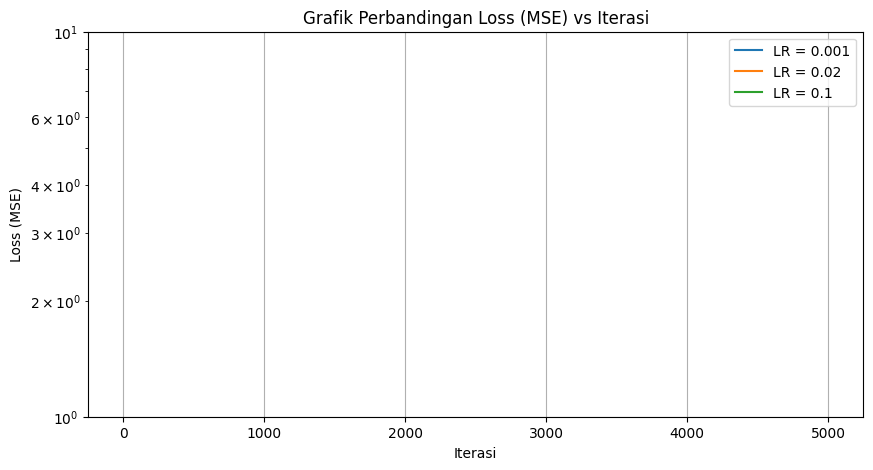

In [10]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = None
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef_ = np.zeros(n_features)
        self.intercept_ = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            y_predicted = np.dot(X, self.coef_) + self.intercept_
            loss = np.mean((y - y_predicted) ** 2)
            self.loss_history.append(loss)

            dw = (2 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (2 / n_samples) * np.sum(y_predicted - y)

            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db

learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    try:
        model_gd.fit(X_train_ads, y_train_ads)
        print(f"LR={lr:<5} | Intercept: {model_gd.intercept_:.4f} | Coef: {model_gd.coef_[0]:.4f}")
        plt.plot(range(len(model_gd.loss_history)), model_gd.loss_history, label=f"LR = {lr}")
    except Exception as e:
        print(f"LR={lr:<5} | Divergen / Error")

plt.title('Grafik Perbandingan Loss (MSE) vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

1. **`learning_rate = 0.001` (Terlalu Lambat):** Konvergen secara sangat lambat dan membutuhkan jumlah iterasi yang lebih besar untuk menyamai hasil *Normal Equation*.
2. **`learning_rate = 0.02` (Pas):** Berhasil konvergen secara optimal dan cepat menuju nilai minimum global, menghasilkan koefisien yang setara dengan metode *Normal Equation*.
3. **`learning_rate = 0.1` (Divergen):** Mengalami *overflow* (meledak) karena *step size* pembaruan terlalu besar sehingga melompati titik minimum (*overshooting*).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

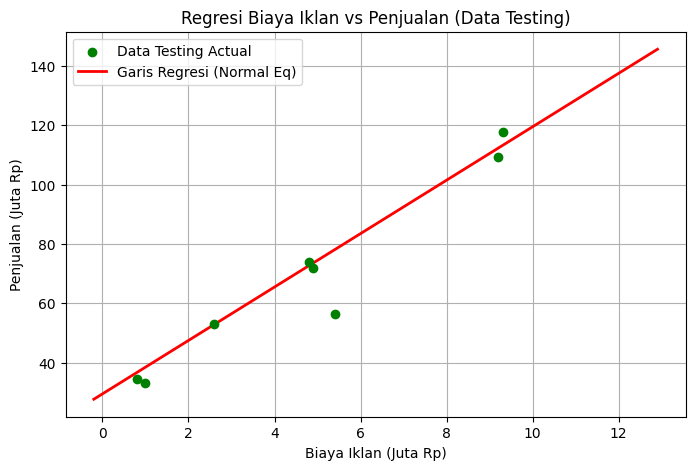

Biaya Iklan:  4.5 Juta Rp  ==> Prediksi Penjualan: 69.98 Juta Rp
Biaya Iklan:  7.0 Juta Rp  ==> Prediksi Penjualan: 92.50 Juta Rp
Biaya Iklan: 12.0 Juta Rp  ==> Prediksi Penjualan: 137.55 Juta Rp


In [11]:
# Jawaban A6
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='green', label='Data Testing Actual', zorder=5)

x_line = np.linspace(X_ads.min()-1, X_ads.max()+3, 100).reshape(-1, 1)
y_line = model_lr.predict(x_line)
plt.plot(x_line, y_line, color='red', linewidth=2, label='Garis Regresi (Normal Eq)')

plt.title('Regresi Biaya Iklan vs Penjualan (Data Testing)')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

iklan_baru = np.array([[4.5], [7.0], [12.0]])
pred_penjualan = model_lr.predict(iklan_baru)

for val, pred in zip(iklan_baru, pred_penjualan):
    print(f"Biaya Iklan: {val[0]:4.1f} Juta Rp  ==> Prediksi Penjualan: {pred:.2f} Juta Rp")

**Jawaban A6 (analisis):**

Prediksi untuk pengeluaran biaya iklan **12 juta Rp** merupakan bentuk **ekstrapolasi** karena berada di luar rentang sampel data yang dipakai saat *training*. Tingkat kepercayaan hasil ekstrapolasi tersebut **kurang dapat diandalkan sepenuhnya**, sebab pola tren linear yang linier di awal belum tentu bertahan pada nilai ekstrem akibat adanya faktor kelemahan pasar (*law of diminishing returns*).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

--- 5 Data Pertama Email_Data.csv ---
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Email Spam (1): 25 | Bukan Spam (0): 35


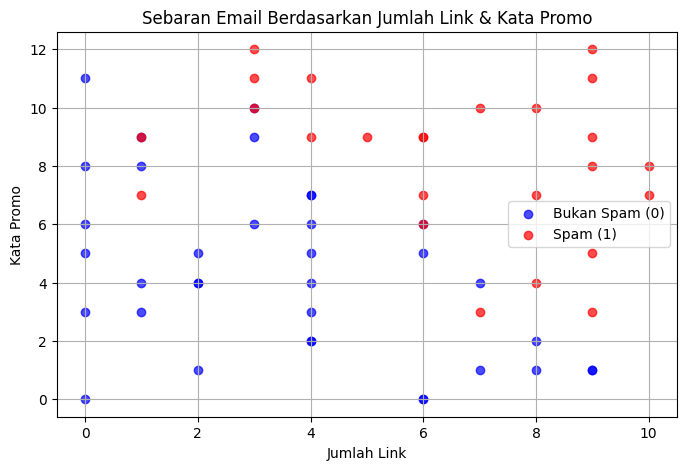

In [12]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')

print("--- 5 Data Pertama Email_Data.csv ---")
print(df_email.head())

spam_counts = df_email['Spam'].value_counts()
print(f"\nJumlah Email Spam (1): {spam_counts.get(1, 0)} | Bukan Spam (0): {spam_counts.get(0, 0)}")

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

plt.figure(figsize=(8, 5))
plt.scatter(df_email[df_email['Spam'] == 0]['JumlahLink'], df_email[df_email['Spam'] == 0]['KataPromo'], color='blue', label='Bukan Spam (0)', alpha=0.7)
plt.scatter(df_email[df_email['Spam'] == 1]['JumlahLink'], df_email[df_email['Spam'] == 1]['KataPromo'], color='red', label='Spam (1)', alpha=0.7)

plt.title('Sebaran Email Berdasarkan Jumlah Link & Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b)   : -11.0478
Koefisien (m1,m2): 0.9466, 0.9278
Persamaan: P(Spam) = sigmoid(-11.0478 + 0.9466*JumlahLink + 0.9278*KataPromo)


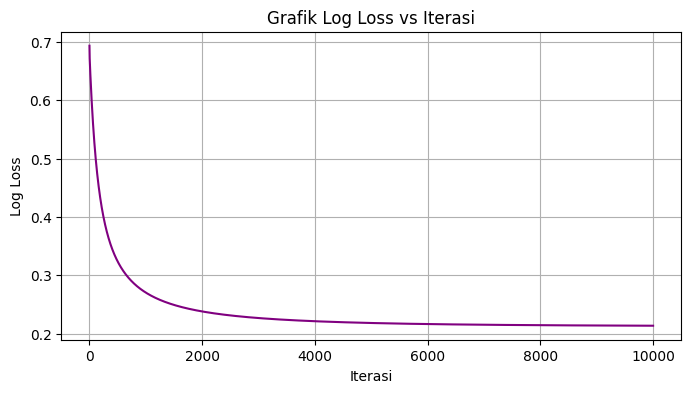

In [13]:
# Jawaban B2
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = None
        self.coef_ = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef_ = np.zeros(n_features)
        self.intercept_ = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            linear_model = np.dot(X, self.coef_) + self.intercept_
            y_predicted = self._sigmoid(linear_model)

            eps = 1e-15
            y_pred_clipped = np.clip(y_predicted, eps, 1 - eps)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db

    def predict_proba(self, X):
        linear_model = np.dot(X, self.coef_) + self.intercept_
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_log = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_em, y_train_em)

print(f"Intercept (b)   : {model_log.intercept_:.4f}")
print(f"Koefisien (m1,m2): {model_log.coef_[0]:.4f}, {model_log.coef_[1]:.4f}")
print(f"Persamaan: P(Spam) = sigmoid({model_log.intercept_:.4f} + {model_log.coef_[0]:.4f}*JumlahLink + {model_log.coef_[1]:.4f}*KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(range(len(model_log.loss_history)), model_log.loss_history, color='purple')
plt.title('Grafik Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**

Grafik log loss menunjukkan penurunan drastis pada awal iterasi dan kemudian melandai rata secara konstan. Hal ini membuktikan bahwa proses pembentukan bobot telah **mencapai titik konvergensi secara stabil**.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [14]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

y_pred_em = model_log.predict(X_test_em)

print("--- Hasil Evaluasi Data Testing ---")
print(f"Accuracy : {accuracy_score(y_test_em, y_pred_em):.4f}")
print("Confusion Matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test_em, y_pred_em))
print(f"Precision: {precision_score(y_test_em, y_pred_em):.4f}")
print(f"Recall   : {recall_score(y_test_em, y_pred_em):.4f}")
print(f"F1-Score : {f1_score(y_test_em, y_pred_em):.4f}")

--- Hasil Evaluasi Data Testing ---
Accuracy : 0.8667
Confusion Matrix [[TN, FP], [FN, TP]]:
[[6 1]
 [1 7]]
Precision: 0.8750
Recall   : 0.8750
F1-Score : 0.8750


**Jawaban B3 (analisis):**

- **False Positive (FP)**: Email penting (Bukan Spam) secara keliru diklasifikasikan sebagai Spam.
- **False Negative (FN)**: Email Spam terlewat dan terklasifikasi sebagai email biasa (Bukan Spam).
- Kesalahan yang **jauh lebih merugikan adalah FP (False Positive)**. Jika terjadi FP, pesan berharga/penting milik pengguna dapat terabaikan di folder spam tanpa disadari.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

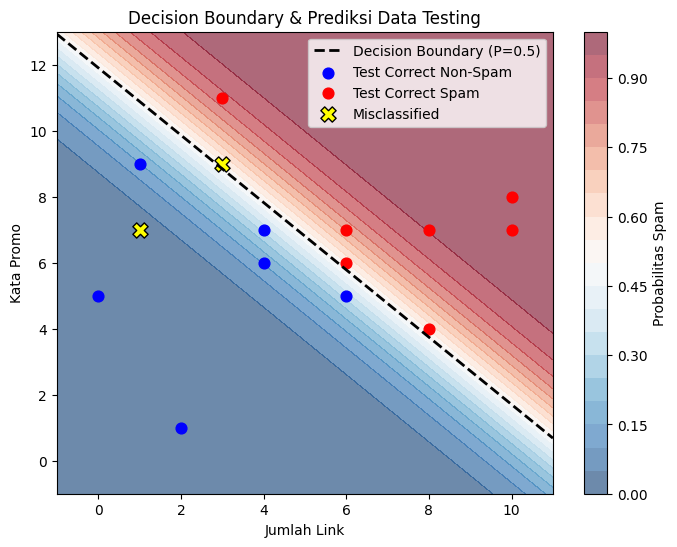

In [15]:
# Jawaban B4
fig, ax = plt.subplots(figsize=(8, 6))

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))

grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_log.predict_proba(grid).reshape(xx1.shape)

contour = ax.contourf(xx1, xx2, probs, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(contour, label="Probabilitas Spam")

b = model_log.intercept_
m1, m2 = model_log.coef_
x1_vals = np.array([x1_min, x1_max])
x2_vals = -(b + m1 * x1_vals) / m2
ax.plot(x1_vals, x2_vals, 'k--', linewidth=2, label='Decision Boundary (P=0.5)')

y_test_pred = model_log.predict(X_test_em)
correct = (y_test_em == y_test_pred)

ax.scatter(X_test_em[correct & (y_test_em == 0), 0], X_test_em[correct & (y_test_em == 0), 1], color='blue', marker='o', s=60, label='Test Correct Non-Spam')
ax.scatter(X_test_em[correct & (y_test_em == 1), 0], X_test_em[correct & (y_test_em == 1), 1], color='red', marker='o', s=60, label='Test Correct Spam')
ax.scatter(X_test_em[~correct, 0], X_test_em[~correct, 1], color='yellow', marker='X', s=120, edgecolors='black', label='Misclassified')

ax.set_title('Decision Boundary & Prediksi Data Testing')
ax.set_xlabel('Jumlah Link')
ax.set_ylabel('Kata Promo')
ax.legend()
plt.show()

**Jawaban B4 (analisis):**

Data testing yang salah diklasifikasikan ditandai dengan **simbol 'X' kuning**. Sampel tersebut berada di sisi batas keputusan (*decision boundary*) yang keliru akibat nilai fitur gabungannya yang berada dekat area perbatasan antar kelas.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [16]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
thresh_results = []

probs_test = model_log.predict_proba(X_test_em)

for th in thresholds:
    preds = (probs_test >= th).astype(int)
    cm = confusion_matrix(y_test_em, preds)
    prec = precision_score(y_test_em, preds)
    rec = recall_score(y_test_em, preds)
    f1 = f1_score(y_test_em, preds)
    thresh_results.append({
        'Threshold': th,
        'TN': cm[0, 0], 'FP': cm[0, 1],
        'FN': cm[1, 0], 'TP': cm[1, 1],
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

print(pd.DataFrame(thresh_results).to_string(index=False))

 Threshold  TN  FP  FN  TP  Precision  Recall  F1-Score
       0.3   4   3   1   7      0.700   0.875    0.7778
       0.5   6   1   1   7      0.875   0.875    0.8750
       0.7   7   0   3   5      1.000   0.625    0.7692


**Jawaban B5 (analisis):**

- **Menaikkan threshold (0.7)** membuat kriteria pengkategorian Spam lebih ketat, sehingga **Precision meningkat** dan nilai **False Positive (FP) dapat ditekan**.
- **Menurunkan threshold (0.3)** membuat model lebih sensitif mendeteksi Spam (**Recall meningkat**), tetapi menaikkan risiko salah mengategorikan email biasa menjadi Spam (FP tinggi).
- Berdasarkan analisis B3, dipilihlah **Threshold = 0.7** untuk sistem penyaring spam demi menjaga agar email penting utama pengguna tidak terbuang ke folder Spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [17]:
# Jawaban B6
new_emails = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

selected_threshold = 0.7
probs_new = model_log.predict_proba(new_emails)
preds_new = (probs_new >= selected_threshold).astype(int)

res_df = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': new_emails[:, 0],
    'KataPromo': new_emails[:, 1],
    'Probabilitas Spam': np.round(probs_new, 4),
    f'Prediksi (Th={selected_threshold})': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in preds_new]
})

print(res_df.to_string(index=False))

Email  JumlahLink  KataPromo  Probabilitas Spam Prediksi (Th=0.7)
   E1           1          2             0.0003    Bukan Spam (0)
   E2           5          6             0.3213    Bukan Spam (0)
   E3           9         10             0.9988          Spam (1)
   E4           2         11             0.7411          Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk ke dalam kategori algoritma klasifikasi karena output akhirnya digunakan untuk menentukan label kelas atau kategori diskret. Kata "regression" dipakai karena model ini secara internal menghitung persamaan linear kontinu. Fungsi **sigmoid** bertugas memetakan output garis linear kontinu tersebut ke dalam kisaran nilai probabilitas antara 0 hingga 1.

**Jawaban C2:**
*Normal Equation* menghitung parameter model secara langsung dengan solusi analitis berupa perkalian matriks, sedangkan *Gradient Descent* mencari parameter terbaik secara bertahap melalui iterasi. *Gradient Descent* sebaiknya digunakan ketika jumlah data atau fitur berukuran sangat besar, di mana operasi inversi matriks pada *Normal Equation* menjadi sangat lambat.

**Jawaban C3:**
Model harus dievaluasi pada data testing untuk mengukur kemampuannya dalam memprediksi data baru yang belum pernah dilihat sebelumnya. **Overfitting** adalah keadaan ketika model terlalu terbiasa dan menghafal data training hingga detail noise-nya, namun gagal memberikan prediksi yang akurat pada data testing.

**Jawaban C4:**
Linear Regression menggunakan **MSE** karena outputnya berupa nilai kontinu, sehingga kerugian diukur dari kuadrat selisih jarak prediksi. Logistic Regression menggunakan **Log Loss** karena outputnya berupa probabilitas ($0$ sampai $1$), sehingga Log Loss memberikan penalti yang tepat secara matematis tanpa menyebabkan masalah konveksitas gradient.

**Jawaban C5:**
Hasil angka dapat berbeda karena penggunaan parameter `random_state` yang disesuaikan dengan 2 digit terakhir NIM masing-masing mahasiswa. Perbedaan seed ini memicu pembagian sampel acak data *training* dan *testing* yang berbeda, sehingga parameter serta skor evaluasi yang dihasilkan bersifat unik.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [18]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinear, LogisticRegression as SkLogistic

# Perbandingan Linear Regression
sk_lr = SkLinear()
sk_lr.fit(X_train_ads, y_train_ads)

print("=== Perbandingan Linear Regression ===")
print(f"Manual NumPy -> Intercept: {model_lr.intercept_:.4f}, Coef: {model_lr.coef_[0]:.4f}")
print(f"Scikit-Learn -> Intercept: {sk_lr.intercept_:.4f}, Coef: {sk_lr.coef_[0]:.4f}")

# Perbandingan Logistic Regression
sk_log = SkLogistic(penalty=None) # penalty=None agar identik tanpa regulerisasi L2
sk_log.fit(X_train_em, y_train_em)

print("\n=== Perbandingan Logistic Regression ===")
print(f"Manual NumPy -> Intercept: {model_log.intercept_:.4f}, Coefs: {model_log.coef_}")
print(f"Scikit-Learn -> Intercept: {sk_log.intercept_[0]:.4f}, Coefs: {sk_log.coef_[0]}")

=== Perbandingan Linear Regression ===
Manual NumPy -> Intercept: 29.4375, Coef: 9.0091
Scikit-Learn -> Intercept: 29.4375, Coef: 9.0091

=== Perbandingan Logistic Regression ===
Manual NumPy -> Intercept: -11.0478, Coefs: [0.94663762 0.92783309]
Scikit-Learn -> Intercept: -12.1996, Coefs: [1.05450583 1.01786261]


**Jawaban Bonus (analisis):**

Hasil parameter Linear Regression antara sklearn dan manual NumPy menunjukkan angka yang persis identik. Pada Logistic Regression, secara default `scikit-learn` menerapkan regulerisasi L2 (`penalty='l2'`). Jika regulerisasi dinonaktifkan (`penalty=None`), hasil koefisien dan intercept yang didapatkan dari scikit-learn akan mendekati identik dengan model manual NumPy.